# Minimum Variance allocator backtested

Run the Minimum Variance allocator through the engine pipeline

In [23]:
# Imports

import pandas as pd
import tabulate
from vportfolio import load_data, pipelines, allocators, plotting
from vportfolio.params import TRIALS_LOG, BACKTEST, ROOT
import matplotlib.pyplot as plt

In [14]:
# load data
data = load_data.load_universe()

In [15]:
# run the pipeline with the min_var allocator

# run it both with the raw covariance matrix and the denoised covariance matrix as input in the allocator
# the output will be logged as a potential allocator candidate
# default lookback and CAP apply as per pre-registration
row_raw = pipelines.trial_pipeline("min_var_raw", allocators.min_var_raw, "candidate", data)
row_dn = pipelines.trial_pipeline("min_var_denoised", allocators.min_var_denoised, "candidate", data)

Expectations:
- The minimum variance allocators should return a lower annualized volatility and maximum drawdown than the other strategies
- The volatility should also improve (lower) with the denoised version
- The average turnover of the denoised min var allocator should be better (lower) than that of the raw min var allocator
- I suspect the return will also be lower given we assign the weights to minimize for volatility, ergo we allocate to the safest ETFs in the space
- Risk adjusted-returns are uncertain: lower volatility bu also lower excess returns

In [16]:
# now let's compare all strategies so far, side by side

log = pd.read_csv(TRIALS_LOG).set_index("name")
log[["role", "ann_return", "ann_vol", "sharpe", "max_drawdown", "avg_turnover"]]

,role,ann_return,ann_vol,sharpe,max_drawdown,avg_turnover
name,,,,,,
sixty_forty,benchmark,0.082404,0.114335,0.649639,-0.356924,0.021518
equal_weights,benchmark,0.057396,0.100348,0.492381,-0.337178,0.037566
risk_weighted,diagnostic,0.041755,0.052478,0.587724,-0.194149,0.034572
hrp,candidate,0.031254,0.037659,0.532284,-0.116845,0.122157
min_var_raw,candidate,0.025989,0.033743,0.438134,-0.140769,0.070282
min_var_denoised,candidate,0.027114,0.033879,0.468796,-0.139661,0.067720


In [17]:
# print the results in a format that I can copy in markdown files
print(log[["role", "ann_return", "ann_vol", "sharpe", "max_drawdown", "avg_turnover"]].round(3).to_markdown())

| name             | role       |   ann_return |   ann_vol |   sharpe |   max_drawdown |   avg_turnover |
|:-----------------|:-----------|-------------:|----------:|---------:|---------------:|---------------:|
| sixty_forty      | benchmark  |        0.082 |     0.114 |    0.65  |         -0.357 |          0.022 |
| equal_weights    | benchmark  |        0.057 |     0.1   |    0.492 |         -0.337 |          0.038 |
| risk_weighted    | diagnostic |        0.042 |     0.052 |    0.588 |         -0.194 |          0.035 |
| hrp              | candidate  |        0.031 |     0.038 |    0.532 |         -0.117 |          0.122 |
| min_var_raw      | candidate  |        0.026 |     0.034 |    0.438 |         -0.141 |          0.07  |
| min_var_denoised | candidate  |        0.027 |     0.034 |    0.469 |         -0.14  |          0.068 |


Observations: 
- Min Var allocator works: lowest volatility and drawdown compared to other allocators
- It does not however pay off in returns --> the Sharpe is the lowest of the five
- The turnover seems quite high for the min var allocators (denoised or not). The allocator likely reshuffles considerably in near-equivalent low volatility assets
- Denoising does help the turnover, with slightly lower value for the denoised version

My understanding of why the denoising effect is relatively small:
- We have a lot of data per each asset; noise is modest for 21 ETFs and 504 days. The ML book shows large gains when data is scarce
- The 20% cap already limits the optimiser. The cap stops the allocator from betting heavily on random correlations, which is what denoising should prevent --> part of the job is already done a priori

**Conclusion**: Denoising moved results in the expected direction (lower turnover, higher Sharpe), but the effect is too small to be meaningful for this universe and lookback. Minimum variance itself delivered the lowest risk but the weakest risk-adjusted return

In [18]:
# rebuild each strategy's NAV (starting at 1) from its saved daily returns

def load_navs(names, folder=BACKTEST):
    returns = {n: pd.read_parquet(folder / f"{n}_returns.parquet")[n] for n in names}
    return (1 + pd.DataFrame(returns)).cumprod()

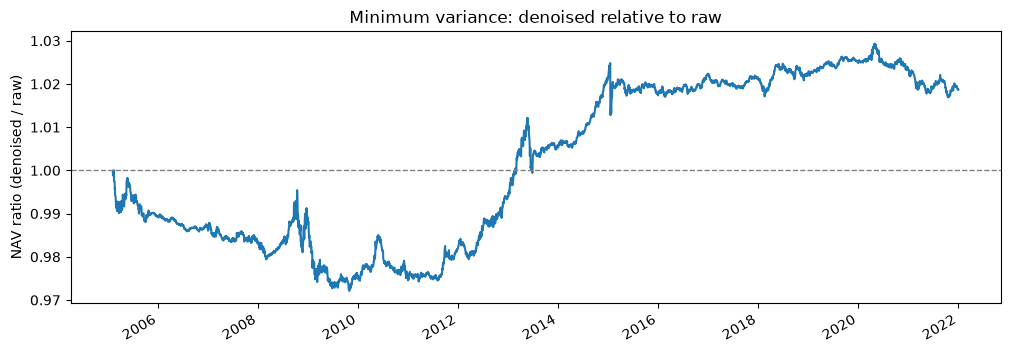

In [25]:
# let's visualize how the allocator's performance changes between raw and denoised inputs

allocators_nav = load_navs(["min_var_raw", "min_var_denoised", "equal_weights", "sixty_forty"])

# we take the ratio of the two to visualize where once performs better than the other
ratio = allocators_nav["min_var_denoised"] / allocators_nav["min_var_raw"]

ax = ratio.plot(figsize=(12, 4), title="Minimum variance: denoised relative to raw")
ax.axhline(1, color="grey", linestyle="--", linewidth=1)   # above 1 = denoised ahead
ax.set_ylabel("NAV ratio (denoised / raw)")
ax.set_xlabel("")
# let's save the picture to add it to the  markdown file
ax.figure.savefig(ROOT / "docs" / "figures" / "min_var_ratio.png", dpi=150, bbox_inches="tight")
plt.show()


Cumulatively, denoising changes returns very little (about +2% over 17 years), consistent with the table. 

The gain is not steady: denoised lags raw until 2012, gains about 5% between 2012 and 2015, and is flat afterwards. The edge therefore comes from one period rather than a consistent effect. The turn coincides with the universe reaching its full 21 ETFs in 2012, which would fit denoising mattering more with more assets, but a single backtest cannot separate this from chance

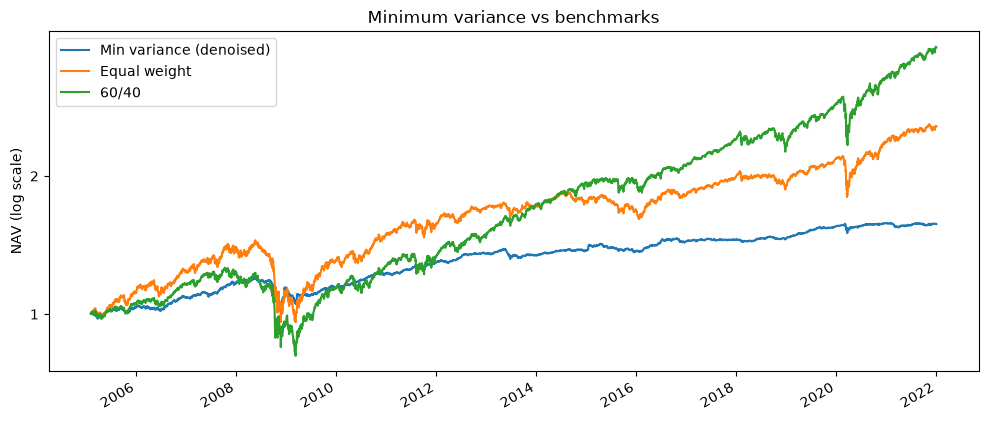

In [27]:
# let's visualize the performance of minimum variance vs benchmark allocators

chart2 = allocators_nav[["min_var_denoised", "equal_weights", "sixty_forty"]].rename(columns={
    "min_var_denoised": "Min variance (denoised)",
    "equal_weights": "Equal weight",
    "sixty_forty": "60/40"})

ax = chart2.plot(logy=True, figsize=(12, 5), title="Minimum variance vs benchmarks")
plotting.format_log_axis(ax)
ax.minorticks_off()
ax.set_ylabel("NAV (log scale)")
ax.set_xlabel("")
plt.show()

In [28]:
# let's save the picture to add it to the  markdown file
ax.figure.savefig(ROOT / "docs" / "figures" / "min_var.png", dpi=150, bbox_inches="tight")
plt.show()

Minimum variance holds up far better in crises: in 2008 it barely dips while equal
weight and 60/40 fall sharply, because it holds the lowest-volatility ETFs (short
Treasuries, the dollar, safe-haven currencies). The same happens on a smaller scale in
March 2020. The cost shows in long expansions: it keeps pace with 60/40 until about
2013, then falls steadily behind as equities rally and its low-volatility holdings earn
little. Its path is the smoothest of the three, but its end value is the lowest.

**Future work**
Each allocator performs best in a different environment: minimum variance in crises
(2008, 2020), equity-heavy allocations in long expansions. A natural extension is a
second model that identifies the current regime and chooses the allocator accordingly
(regime switching; related to meta-labelling in López de Prado, *Advances in Financial
Machine Learning*). It is outside the pre-registered scope: the regime would have to
be detected in real time, not in hindsight, and every regime–allocator combination
would count as an additional trial for the Deflated Sharpe Ratio.